<a href="https://colab.research.google.com/github/joao-araujoo/calculo-numerico/blob/main/interpolacao_erros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/rjlobosco/unifesp/blob/main/Tarefa_Interpolacao_Erros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarefa investigativa: erros em métodos de interpolação

### Aplicação: reconstrução da temperatura em uma barra aquecida

### Nomes: João Pedro Araujo Costa e Rafael Augusto Guimarães da Silva

## 1. Problema físico e equação de transferência de calor

### 1.1 Modelo físico

Considere uma barra sólida homogênea, com comprimento $L=6$ m e seção transversal constante. A temperatura varia principalmente ao longo do eixo $x$. As extremidades são mantidas a temperaturas conhecidas. No interior, uma fonte térmica volumétrica distribui energia ao longo da barra.

A equação geral de energia térmica, para propriedades constantes e sem mudança de fase, pode ser escrita como

$$\rho c_p\frac{\partial T}{\partial t}=k\nabla^2T+\dot q^{\prime\prime\prime}-\rho c_p\,\mathbf{u}\cdot\nabla T,$$

em que $T$ é a temperatura (K ou °C para diferenças), $t$ é o tempo (s), $\rho$ é a massa específica (kg m$^{-3}$), $c_p$ é o calor específico (J kg$^{-1}$ K$^{-1}$), $k$ é a condutividade térmica (W m$^{-1}$ K$^{-1}$), $\dot q^{\prime\prime\prime}$ é a geração volumétrica de calor (W m$^{-3}$) e $\mathbf{u}$ representa o movimento de um fluido, quando há advecção.

Para esta atividade, adotamos uma **barra sólida em regime estacionário**, sem escoamento interno, com condução unidimensional e geração de calor. Assim, $\partial T/\partial t=0$, $\mathbf{u}=0$ e $\nabla^2T=d^2T/dx^2$. A equação fica

$$k\frac{d^2T}{dx^2}+\dot q^{\prime\prime\prime}(x)=0,\qquad 0<x<L,$$

com condições de contorno de Dirichlet

$$T(0)=18\ ^\circ\mathrm C,\qquad T(L)=20.4\ ^\circ\mathrm C.$$

O primeiro termo representa a condução: diferenças espaciais de temperatura geram fluxo de calor. O termo $\dot q^{\prime\prime\prime}(x)$ representa energia adicionada por unidade de volume e de tempo. O sinal positivo de $\dot q^{\prime\prime\prime}$ indica geração interna de calor.

### 1.2 Perfil de referência usado no experimento

Para criar um caso com solução conhecida, definimos $\xi=x/L$ e adotamos

$$T(x)=18+2.4\,\xi+2.5\sin(\pi\xi),\qquad \xi=\frac{x}{L},\quad 0\le x\le L.$$

A parcela linear garante as temperaturas prescritas nas extremidades. A parcela senoidal representa um aquecimento distribuído mais intenso no interior e nulo nas bordas. Derivando duas vezes em relação à coordenada física $x$,

$$\frac{d^2T}{dx^2}=-\frac{2.5\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Portanto, esse perfil satisfaz a equação estacionária se a geração volumétrica for

$$\dot q^{\prime\prime\prime}(x)=\frac{2.5\,k\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Como $\sin(\pi x/L)\ge0$ dentro da barra, a fonte é não negativa. Não precisamos escolher um valor numérico para $k$: o objetivo é verificar a coerência do perfil e estudar a interpolação. A função analítica é uma referência idealizada; em uma aplicação experimental, seria preciso estimar propriedades, fontes, perdas e condições de contorno.


### O que significa erro de interpolação?

Em um ponto de avaliação $x$, o erro assinado é $e(x)=p(x)-T(x)$. O erro absoluto é $|e(x)|$. Como a interpolação reproduz os nós, o erro nesses pontos pode ser praticamente zero; por isso, avaliaremos também muitos pontos **entre** os nós.

Usaremos: erro máximo absoluto $E_{max}=\max_j|e_j|$; erro médio absoluto (MAE) $=\frac{1}{m}\sum_j|e_j|$; raiz do erro quadrático médio (RMSE) $=\sqrt{\frac{1}{m}\sum_j e_j^2}$. O RMSE penaliza mais erros grandes.

## 2. Figura do problema e preparação do ambiente

A figura esquematiza a barra, os sensores, as temperaturas nas extremidades e a fonte térmica interna. A curva corresponde ao perfil de referência usado no experimento. Os pontos são as posições onde os sensores amostram a temperatura.

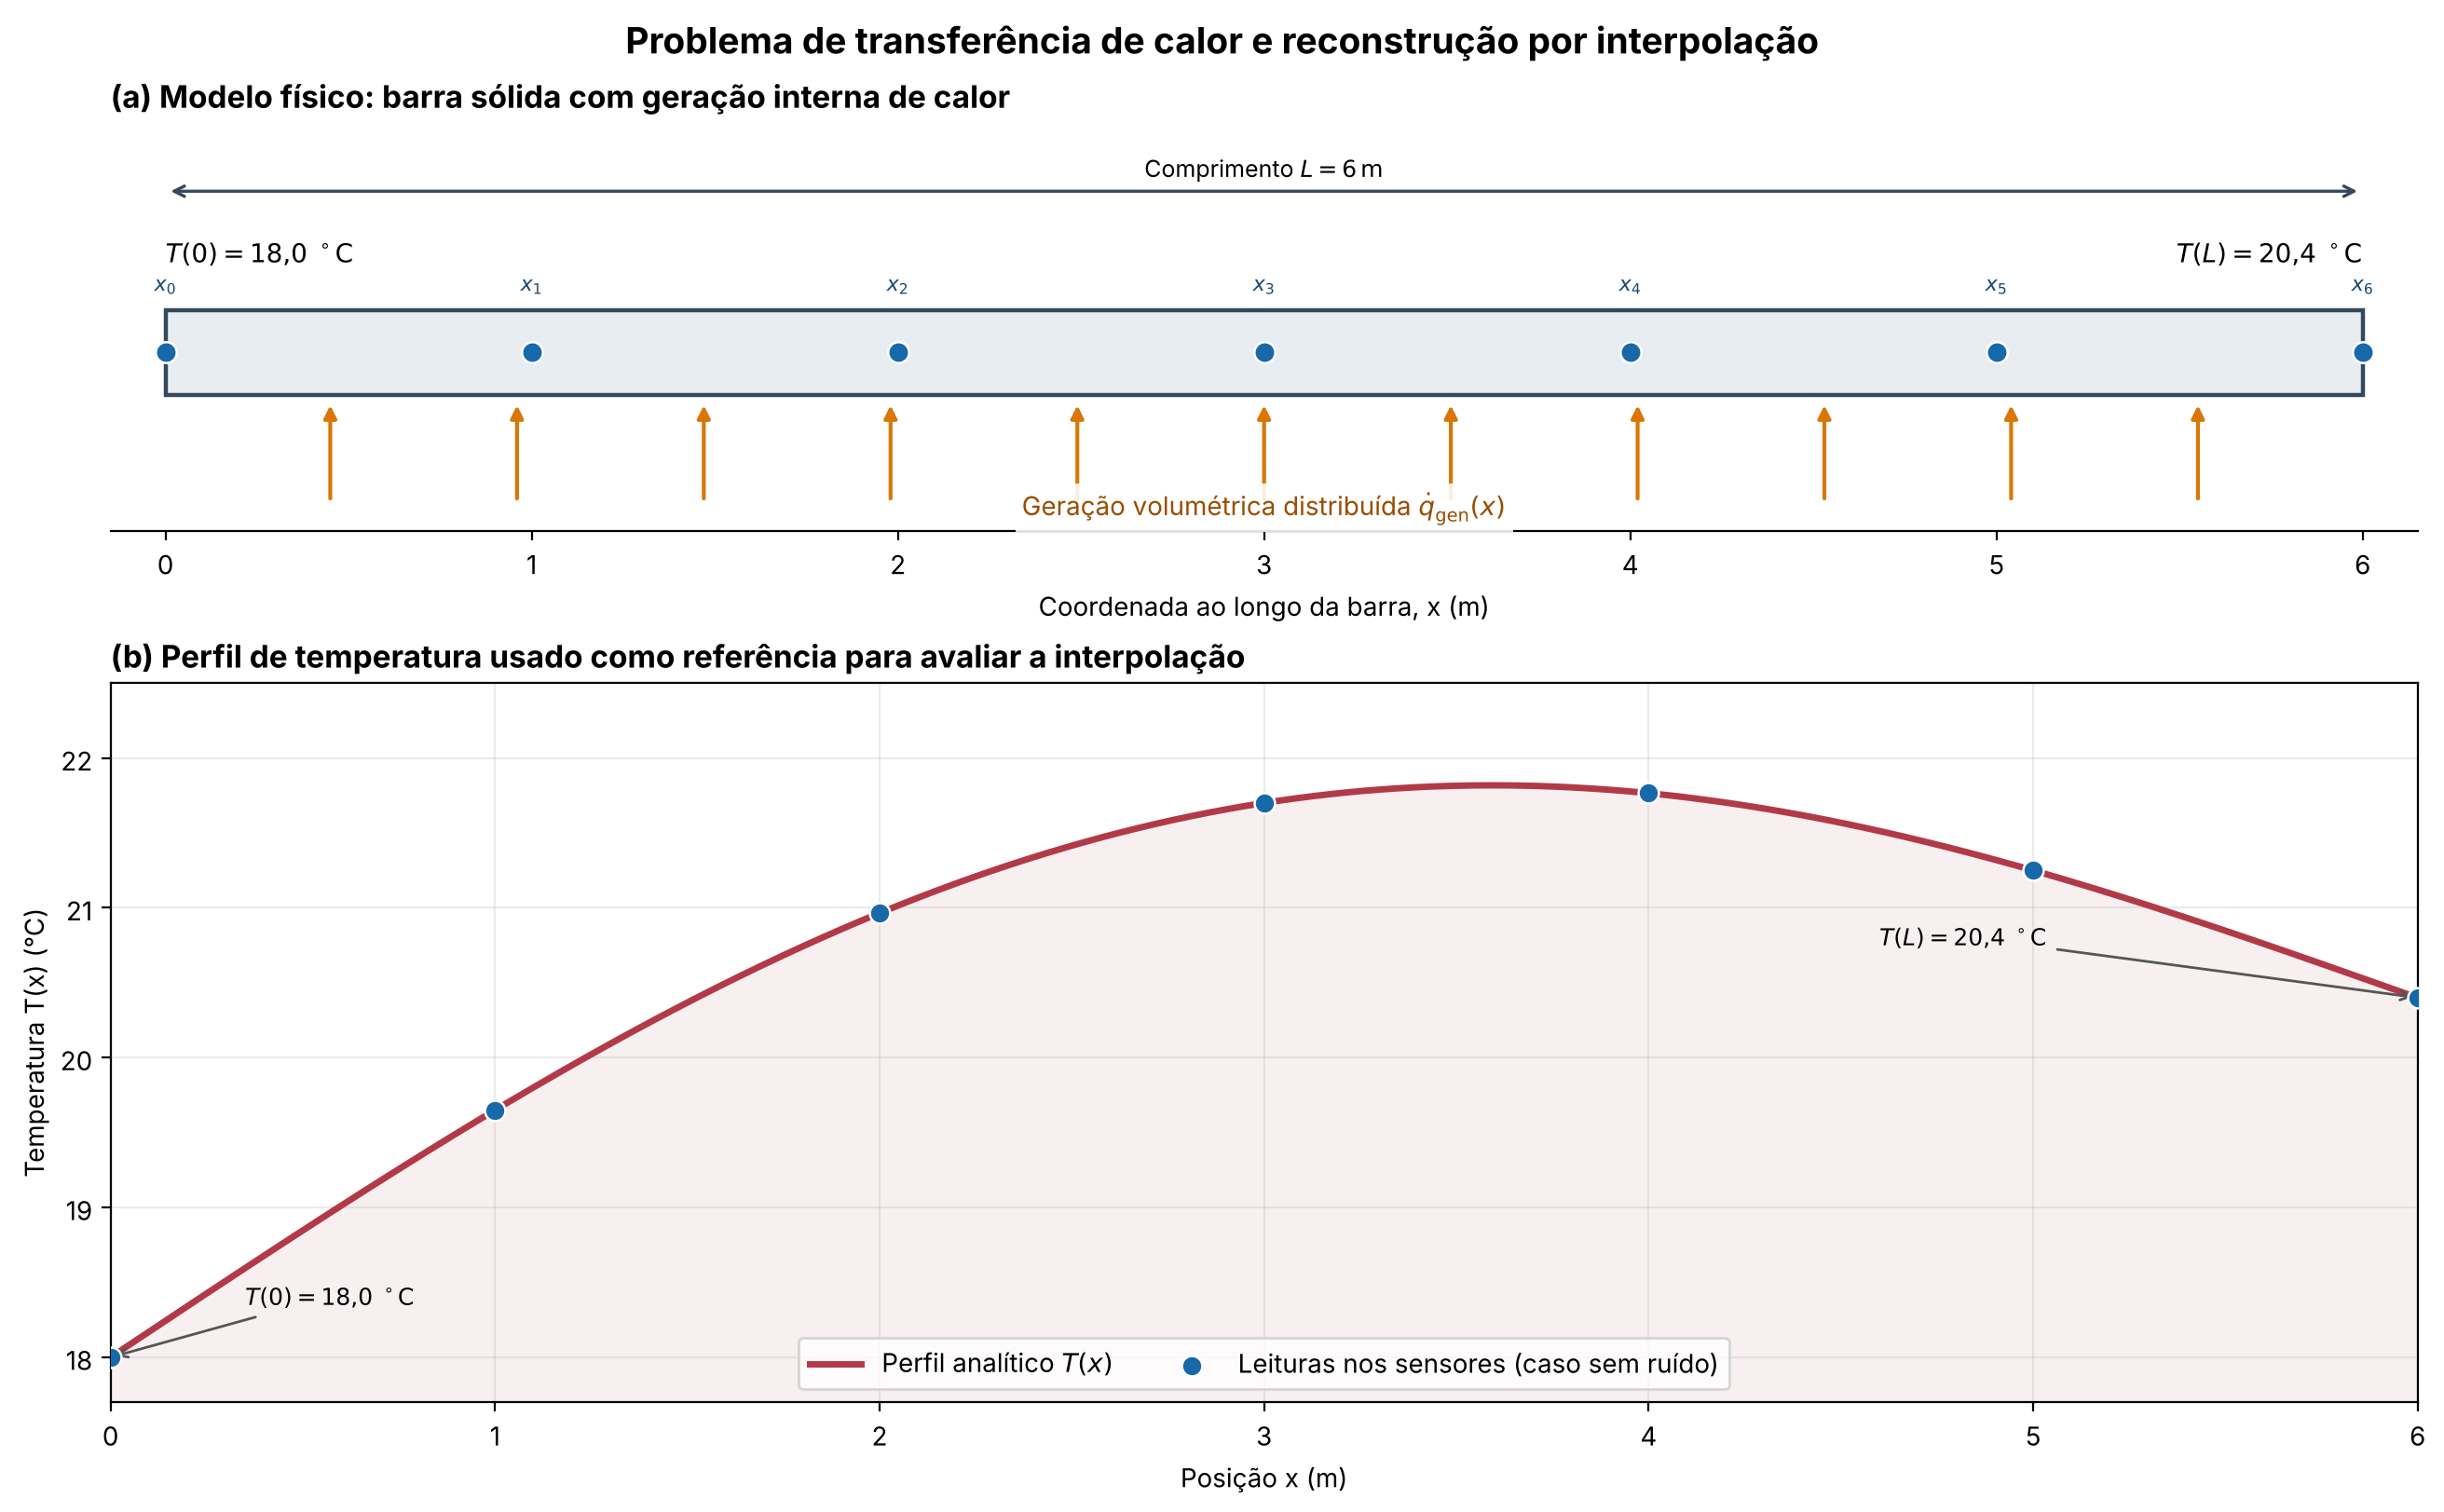

Temperaturas nas extremidades: T(0)=18.0 °C e T(L)=20.4 °C


In [ ]:
# Preparação do modelo e bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator, interp1d, CubicSpline
from matplotlib.patches import Rectangle

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (9, 5)
L = 6.0  # comprimento da barra, m

def temperatura_real(x):
    """Perfil analítico de referência em °C; x é dado em metros."""
    x = np.asarray(x, dtype=float)
    xi = x/L
    return 18 + 2.4*xi + 2.5*np.sin(np.pi*xi)

x_min, x_max = 0.0, L
x_fino = np.linspace(x_min, x_max, 2001)
T_fino = temperatura_real(x_fino)

# Figura do problema: esquema físico e perfil analítico em painéis separados

x_sensores_fig = np.linspace(0, L, 7)
T_sensores_fig = temperatura_real(x_sensores_fig)

fig = plt.figure(figsize=(13, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[0.85, 1.5])
ax_esq = fig.add_subplot(gs[0])
ax_perfil = fig.add_subplot(gs[1])

# Painel (a): barra física, sensores e fonte interna distribuída
ax_esq.set_title("(a) Modelo físico: barra sólida com geração interna de calor", loc="left", fontsize=12, weight="bold")
barra_y, barra_h = 0.40, 0.25
ax_esq.add_patch(Rectangle((0, barra_y), L, barra_h, facecolor="#e8edf2",
                           edgecolor="#34495e", linewidth=1.6, zorder=1))
# Sensores ao longo do eixo da barra
ax_esq.scatter(x_sensores_fig, np.full_like(x_sensores_fig, barra_y+barra_h/2),
               s=65, marker="o", facecolor="#1769aa", edgecolor="white", linewidth=0.9,
               zorder=4, label="Sensores")
# Aquecimento interno: setas iguais identificam geração distribuída, sem sugerir fluxo de calor externo
for xpos in np.linspace(0.45, 5.55, 11):
    ax_esq.annotate("", xy=(xpos, barra_y-0.015), xytext=(xpos, 0.08),
                    arrowprops={"arrowstyle":"-|>", "color":"#d97706", "lw":1.5}, zorder=3)
ax_esq.text(L/2, 0.015, r"Geração volumétrica distribuída $\dot{q}_{\mathrm{gen}}(x)$",
            ha="center", va="bottom", color="#9a4d00", fontsize=10,
            bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.88, "pad":2.5})
ax_esq.text(0, 0.77, r"$T(0)=18{,}0\ ^\circ\mathrm{C}$", ha="left", va="bottom", fontsize=10)
ax_esq.text(L, 0.77, r"$T(L)=20{,}4\ ^\circ\mathrm{C}$", ha="right", va="bottom", fontsize=10)
# Linha de dimensão e eixo longitudinal
ax_esq.annotate("", xy=(L, 1.00), xytext=(0, 1.00),
                arrowprops={"arrowstyle":"<->", "color":"#34495e", "lw":1.2})
ax_esq.text(L/2, 1.025, r"Comprimento $L=6\,\mathrm{m}$", ha="center", va="bottom", fontsize=9)
for i, xpos in enumerate(x_sensores_fig):
    ax_esq.text(xpos, barra_y+barra_h+0.04, rf"$x_{i}$", ha="center", va="bottom", fontsize=8, color="#174a73")
ax_esq.set_xlim(-0.15, L+0.15); ax_esq.set_ylim(0, 1.2)
ax_esq.set_xlabel("Coordenada ao longo da barra, x (m)")
ax_esq.set_yticks([]); ax_esq.grid(False)
for spine in ["left", "right", "top"]: ax_esq.spines[spine].set_visible(False)

# Painel (b): curva de referência e posições amostradas
ax_perfil.set_title("(b) Perfil de temperatura usado como referência para avaliar a interpolação",
                    loc="left", fontsize=12, weight="bold")
ax_perfil.plot(x_fino, T_fino, color="#b23a48", linewidth=2.5,
               label=r"Perfil analítico $T(x)$", zorder=2)
ax_perfil.scatter(x_sensores_fig, T_sensores_fig, s=62, marker="o",
                  facecolor="#1769aa", edgecolor="white", linewidth=0.9,
                  label="Leituras nos sensores (caso sem ruído)", zorder=4)
ax_perfil.fill_between(x_fino, T_fino, np.min(T_fino)-0.3,
                       color="#b23a48", alpha=0.08, zorder=1)
ax_perfil.annotate(r"$T(0)=18{,}0\ ^\circ\mathrm{C}$",
                   xy=(0, temperatura_real(0)), xytext=(0.35, 18.35),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.annotate(r"$T(L)=20{,}4\ ^\circ\mathrm{C}$",
                   xy=(L, temperatura_real(L)), xytext=(4.6, 20.75),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.set_xlim(0, L); ax_perfil.set_ylim(17.7, 22.5)
ax_perfil.set_xlabel("Posição x (m)")
ax_perfil.set_ylabel("Temperatura T(x) (°C)")
ax_perfil.grid(True, alpha=0.25); ax_perfil.legend(loc="lower center", ncol=2, frameon=True)
fig.suptitle("Problema de transferência de calor e reconstrução por interpolação", fontsize=14, weight="bold")
plt.show()

print(f"Temperaturas nas extremidades: T(0)={temperatura_real(0):.1f} °C e T(L)={temperatura_real(L):.1f} °C")

Spline quadrática

In [ ]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## 3. Métodos de interpolação e métricas de erro

O interpolador global de Lagrange passa por todos os sensores usando um único polinômio. Usamos a forma baricêntrica, que evita expandir diretamente os coeficientes e costuma ser numericamente mais estável.

As splines constroem polinômios por intervalos. A spline linear conecta pontos por retas. A quadrática deste notebook impõe continuidade da função e da primeira derivada e usa a condição de contorno $c_0=0$ no primeiro intervalo. A spline cúbica natural impõe continuidade até a segunda derivada e segunda derivada nula nas extremidades.

Para quantificar a diferença, calculamos $e(x)=T_{interp}(x)-T_{ref}(x)$. O erro máximo mostra o pior desvio na malha. O MAE dá o desvio absoluto médio. O RMSE penaliza mais os erros de grande magnitude. Todos têm unidade de graus Celsius.

A malha fina serve como conjunto de pontos de avaliação: os valores nela não são novos sensores. Assim, a comparação mede desempenho entre os nós.

In [ ]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## Etapa 1 — Interpolação com dados exatos
Suponha primeiro que os sensores sejam perfeitos. Coloque sete sensores em posições igualmente espaçadas, incluindo as duas extremidades. Os valores registrados são então exatamente $T(x_i)$.

### Passo a passo
1. Construa o vetor das posições e avalie o perfil de referência nesses pontos.
2. Crie a interpolação com `criar_metodos`.
3. Avalie cada método em `x_fino`, uma malha densa entre 0 e 6 m.
4. Calcule $E_{max}$, MAE e RMSE comparando cada curva com `T_fino`.
5. Faça um gráfico das temperaturas e outro dos erros assinados.




,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Lagrange global,8.468e-05,1.918e-05,3.271e-05
1,Spline cúbica natural,5.060e-04,1.841e-04,2.391e-04
2,Spline quadrática,2.393e-02,1.495e-02,1.647e-02
3,Spline linear,8.229e-02,3.651e-02,4.397e-02


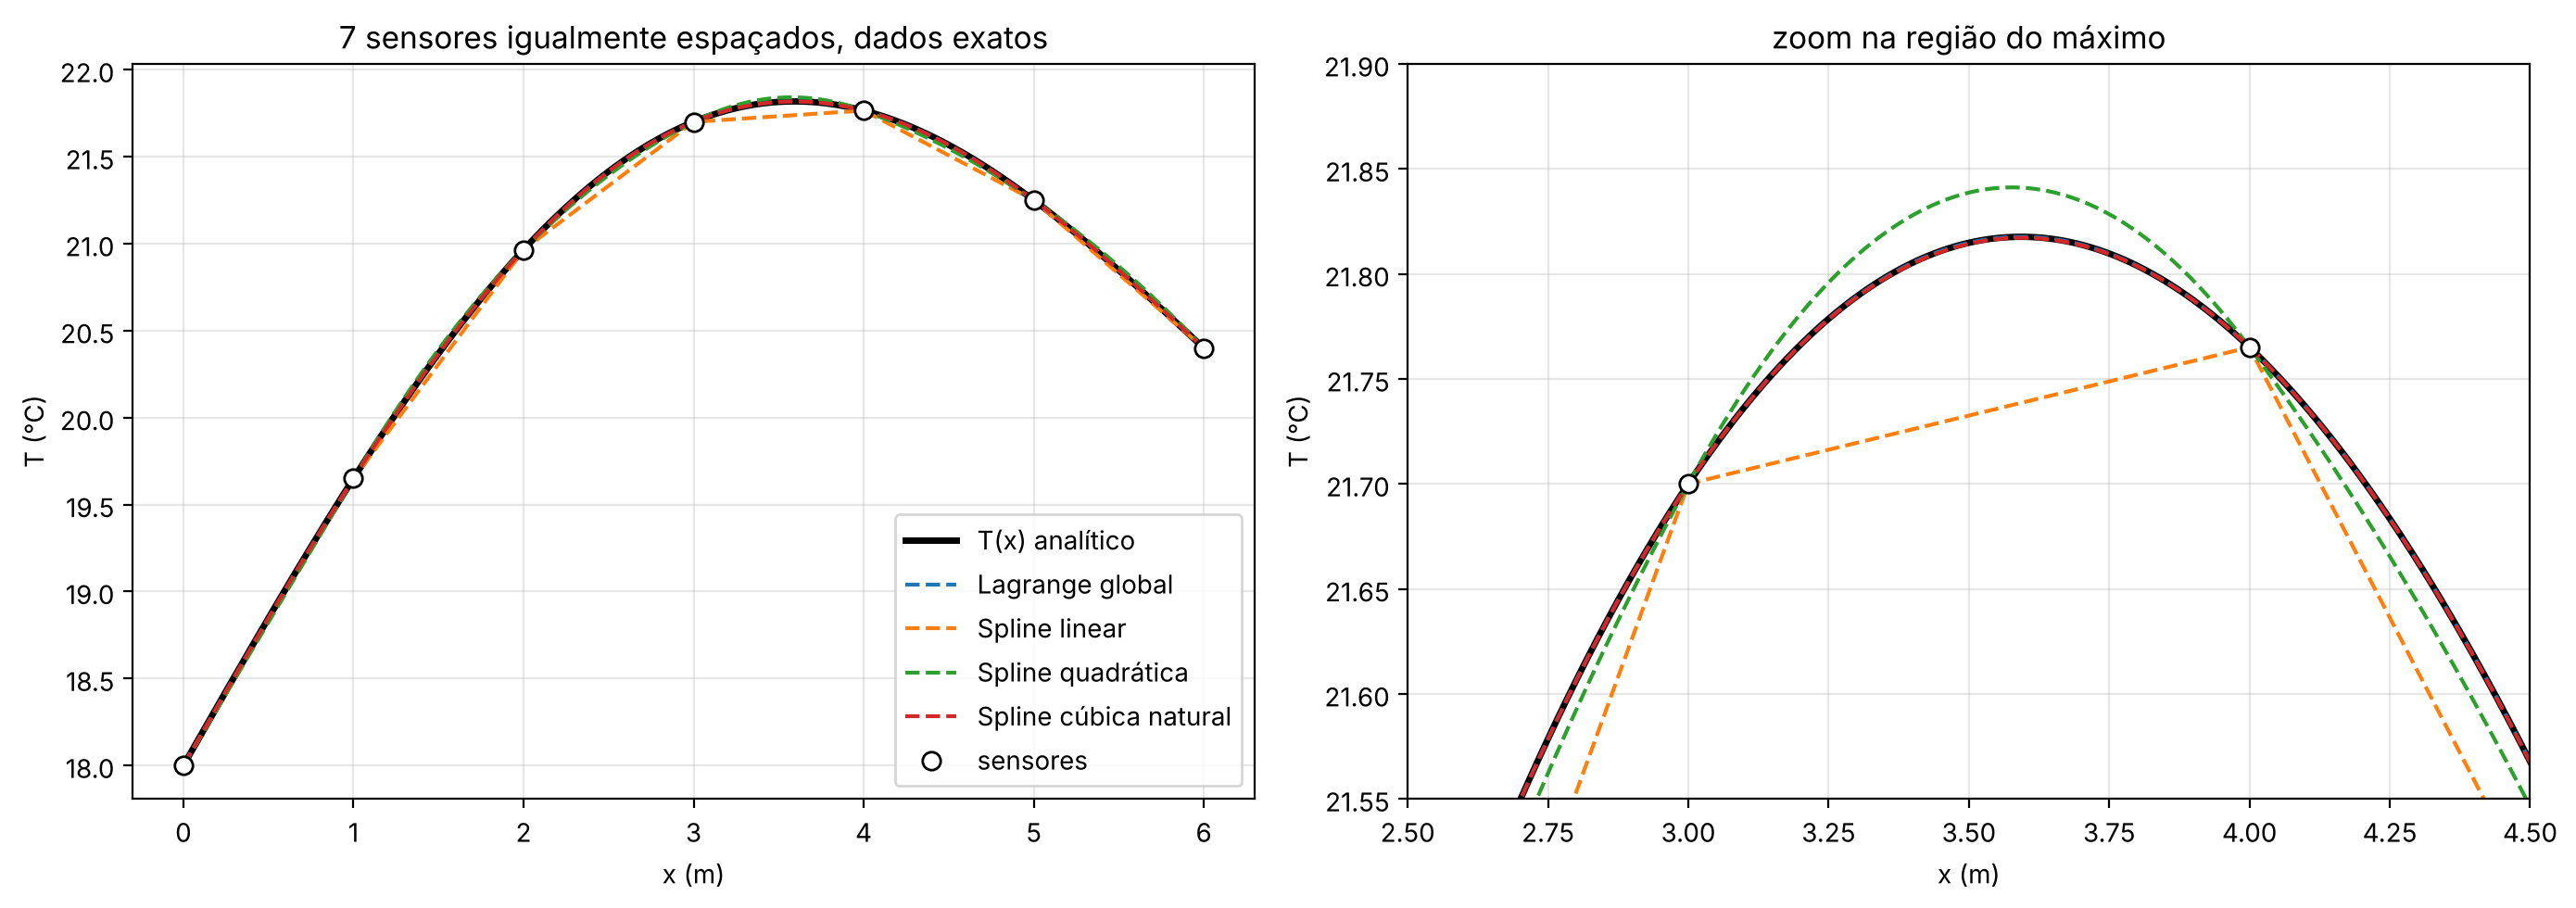

Lagrange global: maior |erro| = 8.47e-05 °C em x = 5.706 m
Spline linear: maior |erro| = 8.23e-02 °C em x = 2.505 m
Spline quadrática: maior |erro| = 2.39e-02 °C em x = 3.519 m
Spline cúbica natural: maior |erro| = 5.06e-04 °C em x = 3.507 m


In [ ]:
pd.set_option("display.float_format", "{:.3e}".format)

x_nos_7 = np.linspace(x_min, x_max, 7)
y_nos_7 = temperatura_real(x_nos_7)
metodos_7 = criar_metodos(x_nos_7, y_nos_7)

metricas_7 = calcular_metricas(metodos_7, x_fino, T_fino)
display(metricas_7)

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for ax in axs:
    ax.plot(x_fino, T_fino, color="k", lw=2.5, label="T(x) analítico")
    for nome, metodo in metodos_7.items():
        ax.plot(x_fino, metodo(x_fino), "--", lw=1.5, label=nome)
    ax.plot(x_nos_7, y_nos_7, "o", color="k", mfc="white", ms=7, label="sensores")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("T (°C)")
    ax.grid(alpha=0.3)
axs[0].set_title("7 sensores igualmente espaçados, dados exatos")
axs[0].legend()
axs[1].set_xlim(2.5, 4.5)
axs[1].set_ylim(21.55, 21.9)
axs[1].set_title("zoom na região do máximo")
plt.tight_layout()
plt.show()

for nome, metodo in metodos_7.items():
    erro = metodo(x_fino) - T_fino
    j = np.argmax(np.abs(erro))
    print(f"{nome}: maior |erro| = {abs(erro[j]):.2e} °C em x = {x_fino[j]:.3f} m")

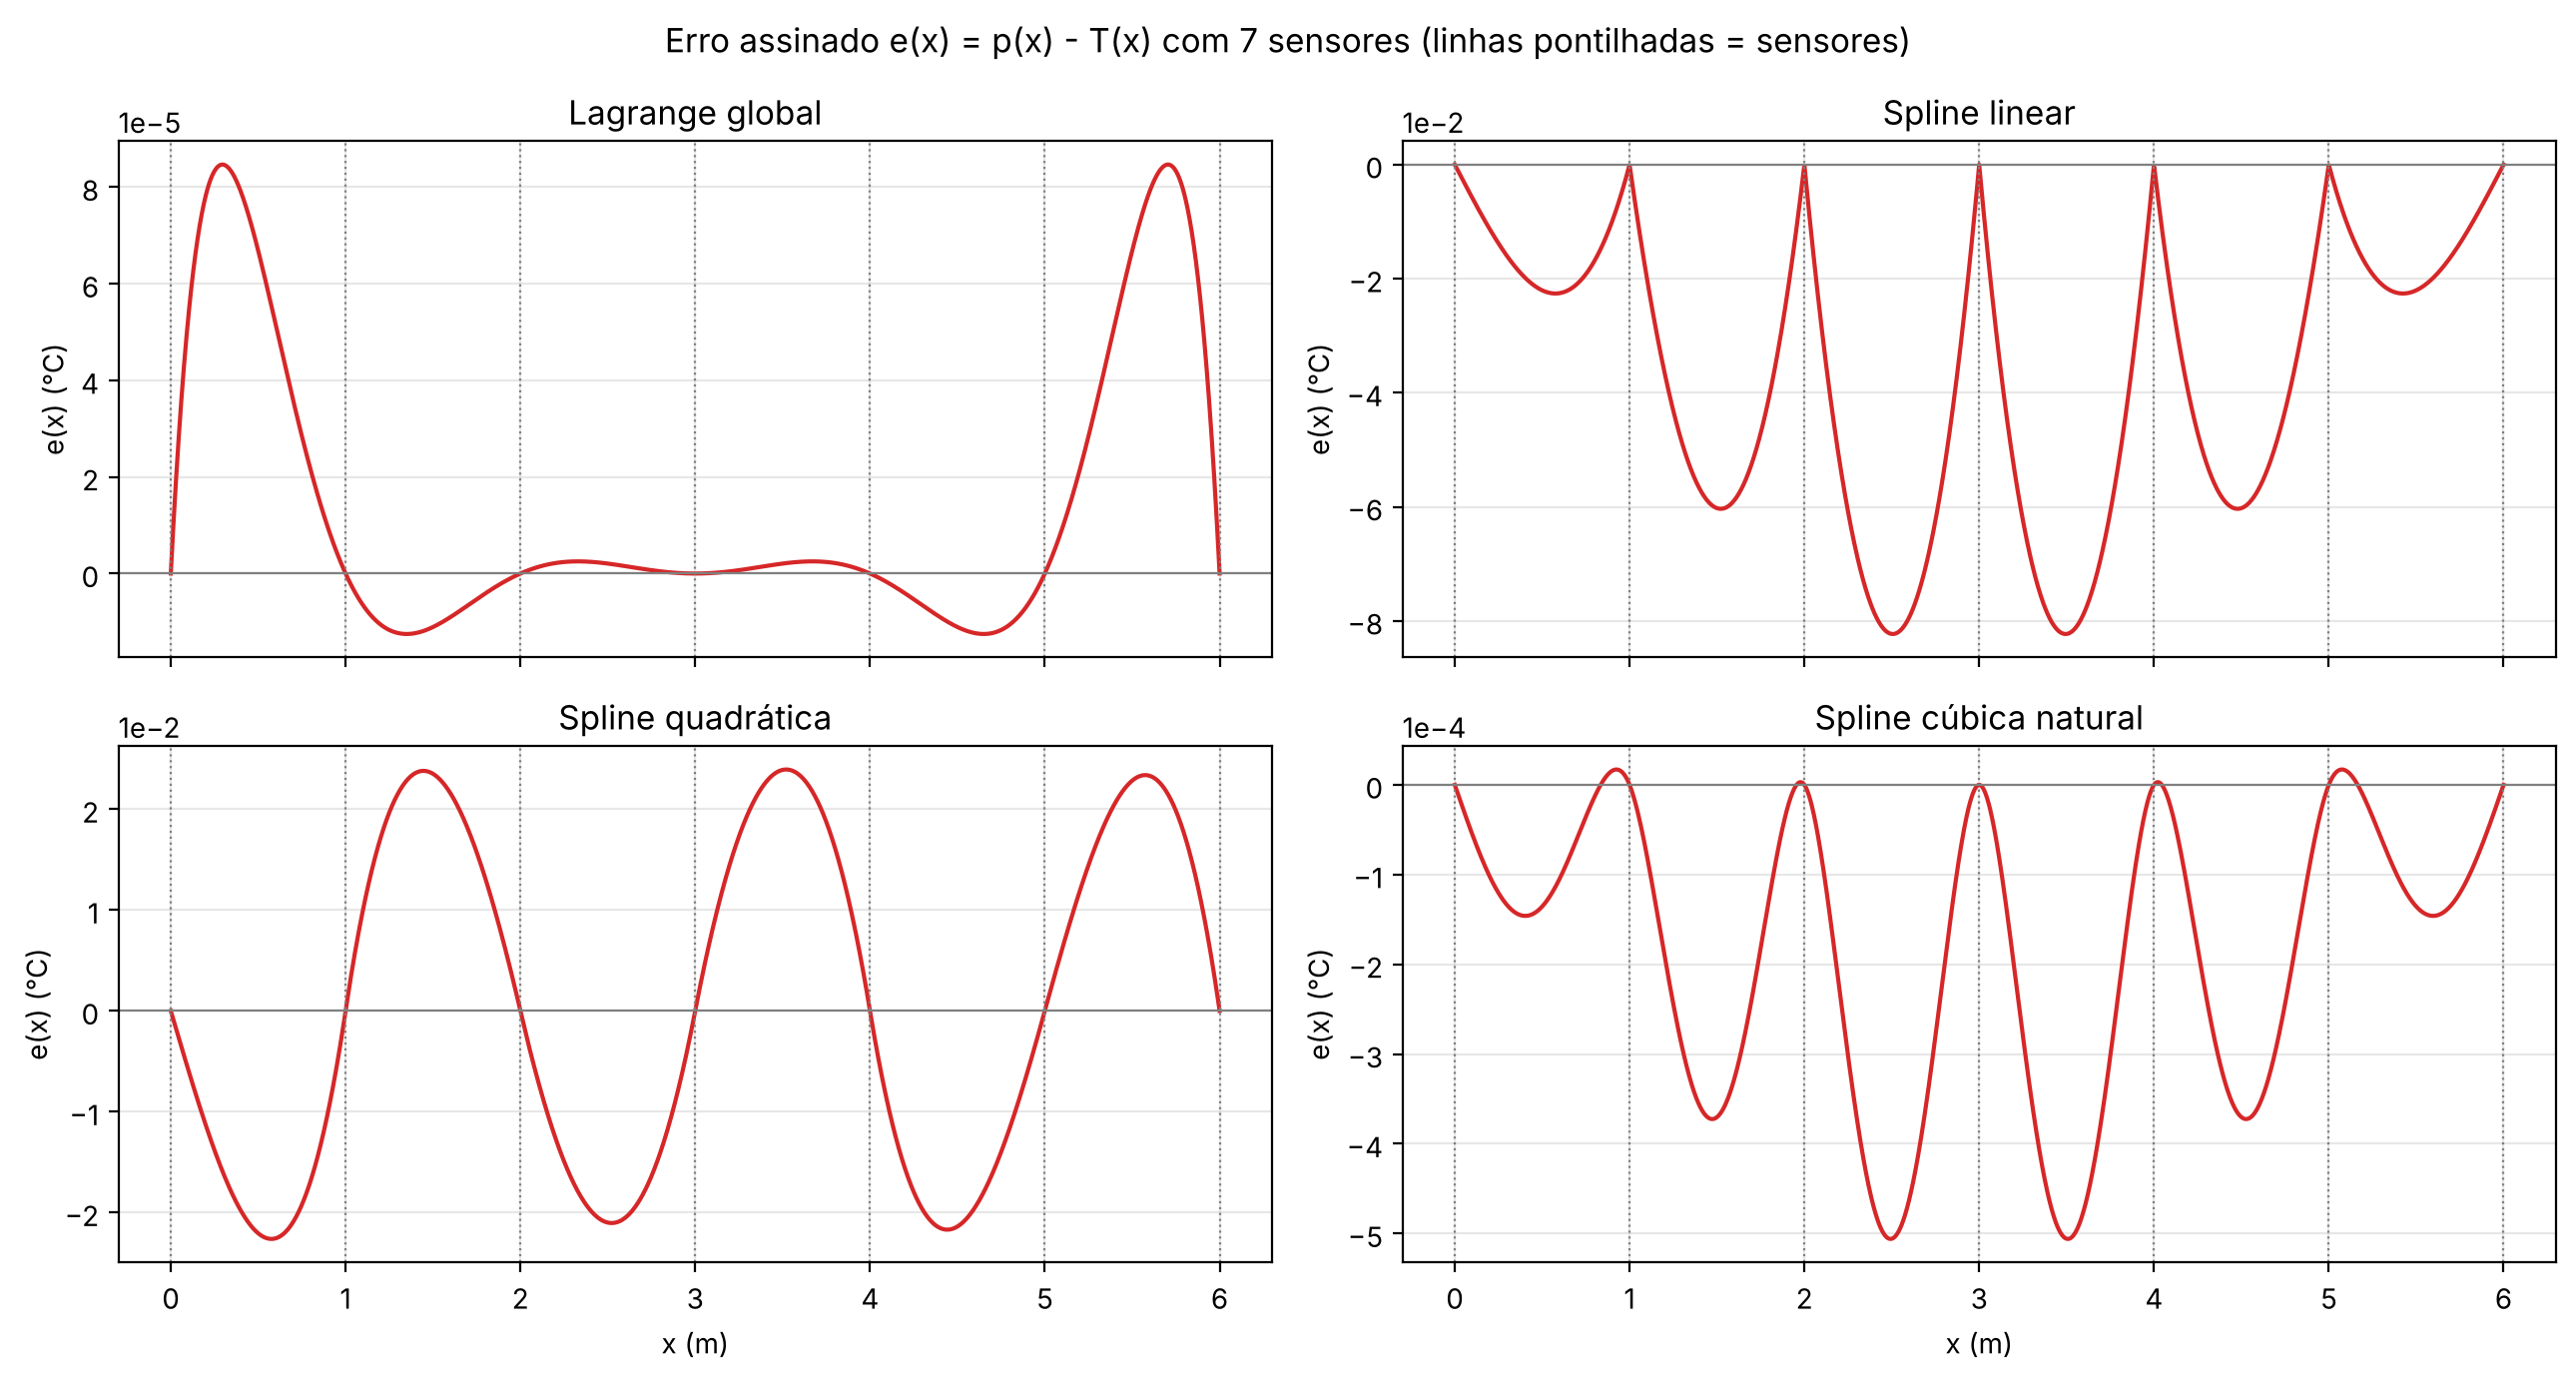

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for ax, (nome, metodo) in zip(axs.ravel(), metodos_7.items()):
    erro = metodo(x_fino) - T_fino
    ax.plot(x_fino, erro, color="tab:red")
    ax.axhline(0, color="gray", lw=0.8)
    for xn in x_nos_7:
        ax.axvline(xn, color="gray", ls=":", lw=0.8)
    ax.set_title(nome)
    ax.set_ylabel("e(x) (°C)")
    ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2))
    ax.grid(alpha=0.3)
for ax in axs[1]:
    ax.set_xlabel("x (m)")
fig.suptitle("Erro assinado e(x) = p(x) - T(x) com 7 sensores (linhas pontilhadas = sensores)")
plt.tight_layout()
plt.show()

Análise da etapa 1

Com 7 sensores o Lagrange global teve o menor erro (Emax = 8,5e-5 °C e RMSE = 3,3e-5 °C), seguido da spline cúbica natural (Emax = 5,1e-4 °C e RMSE = 2,4e-4 °C). A quadrática e a linear ficaram bem piores, com Emax de 0,024 °C e 0,082 °C. No gráfico das temperaturas só essas duas se separam da curva verdadeira, e mesmo assim só perto do máximo.

Pelo gráfico dos erros dá pra ver que cada método erra de um jeito. A linear erra sempre pra baixo, porque a curva é côncava e a reta entre dois sensores fica abaixo dela. A quadrática fica oscilando com o mesmo tamanho de erro na barra toda, porque a condição c_0 = 0 deixa o primeiro trecho reto e esse erro vai sendo passado pros trechos seguintes. O Lagrange erra mais perto das pontas (x ≈ 0,3 m e 5,7 m) e quase nada no meio. Já a spline cúbica erra mais no meio e pouco nas pontas, mas isso é meio sorte: nesse perfil T'' = 0 nas extremidades, que é justamente a condição da spline natural.

## Etapa 2 — Número e posição dos sensores

Nesta etapa, investigue somente o polinômio global de Lagrange. A interpolação polinomial global pode oscilar entre nós, sobretudo perto das extremidades, quando se usam muitos nós equiespaçados. A distribuição de Chebyshev concentra nós nas bordas e pode reduzir esse efeito.

Para $N$ nós de Chebyshev-Lobatto em $[a,b]$, use

$$x_k=\frac{a+b}{2}+\frac{b-a}{2}\cos\left(\frac{k\pi}{N-1}\right),\quad k=0,\ldots,N-1.$$

Ordene as posições crescentemente. Compare $N=5,9,13,17$ para nós equiespaçados e de Chebyshev. Para cada caso, avalie o erro em todos os pontos da malha fina e registre o erro máximo e o RMSE.

**Atenção:** uma redução de erro neste perfil particular não prova que o mesmo ocorrerá para qualquer função. Relacione a observação à suavidade e à estrutura do perfil usado.

In [ ]:
def nos_chebyshev_lobatto(a, b, N):
    k = np.arange(N)
    z = np.cos(k*np.pi/(N-1))
    return np.sort((a+b)/2 + (b-a)*z/2)

linhas = []
for N in [5, 9, 13, 17]:
    for tipo, xs in [("equiespaçado", np.linspace(x_min, x_max, N)),
                     ("Chebyshev", nos_chebyshev_lobatto(x_min, x_max, N))]:
        p = BarycentricInterpolator(xs, temperatura_real(xs))
        erro = p(x_fino) - T_fino
        linhas.append({"N": N, "Nós": tipo,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})

tabela_nos = pd.DataFrame(linhas)
display(tabela_nos)

comparacao = tabela_nos.pivot(index="N", columns="Nós", values="Erro máximo (°C)")
comparacao["Emax equi / Emax Cheb"] = comparacao["equiespaçado"] / comparacao["Chebyshev"]
display(comparacao)

,N,Nós,Erro máximo (°C),RMSE (°C)
0,5,equiespaçado,4.530e-03,2.160e-03
1,5,Chebyshev,2.327e-03,1.533e-03
2,9,equiespaçado,1.044e-06,3.438e-07
3,9,Chebyshev,2.168e-07,1.202e-07
4,13,equiespaçado,5.911e-11,1.545e-11
5,13,Chebyshev,3.624e-12,1.932e-12
6,17,equiespaçado,1.990e-12,2.445e-13
7,17,Chebyshev,1.421e-14,3.848e-15


Nós,Chebyshev,equiespaçado,Emax equi / Emax Cheb
N,,,
5,2.327e-03,4.530e-03,1.947e+00
9,2.168e-07,1.044e-06,4.814e+00
13,3.624e-12,5.911e-11,1.631e+01
17,1.421e-14,1.990e-12,1.400e+02


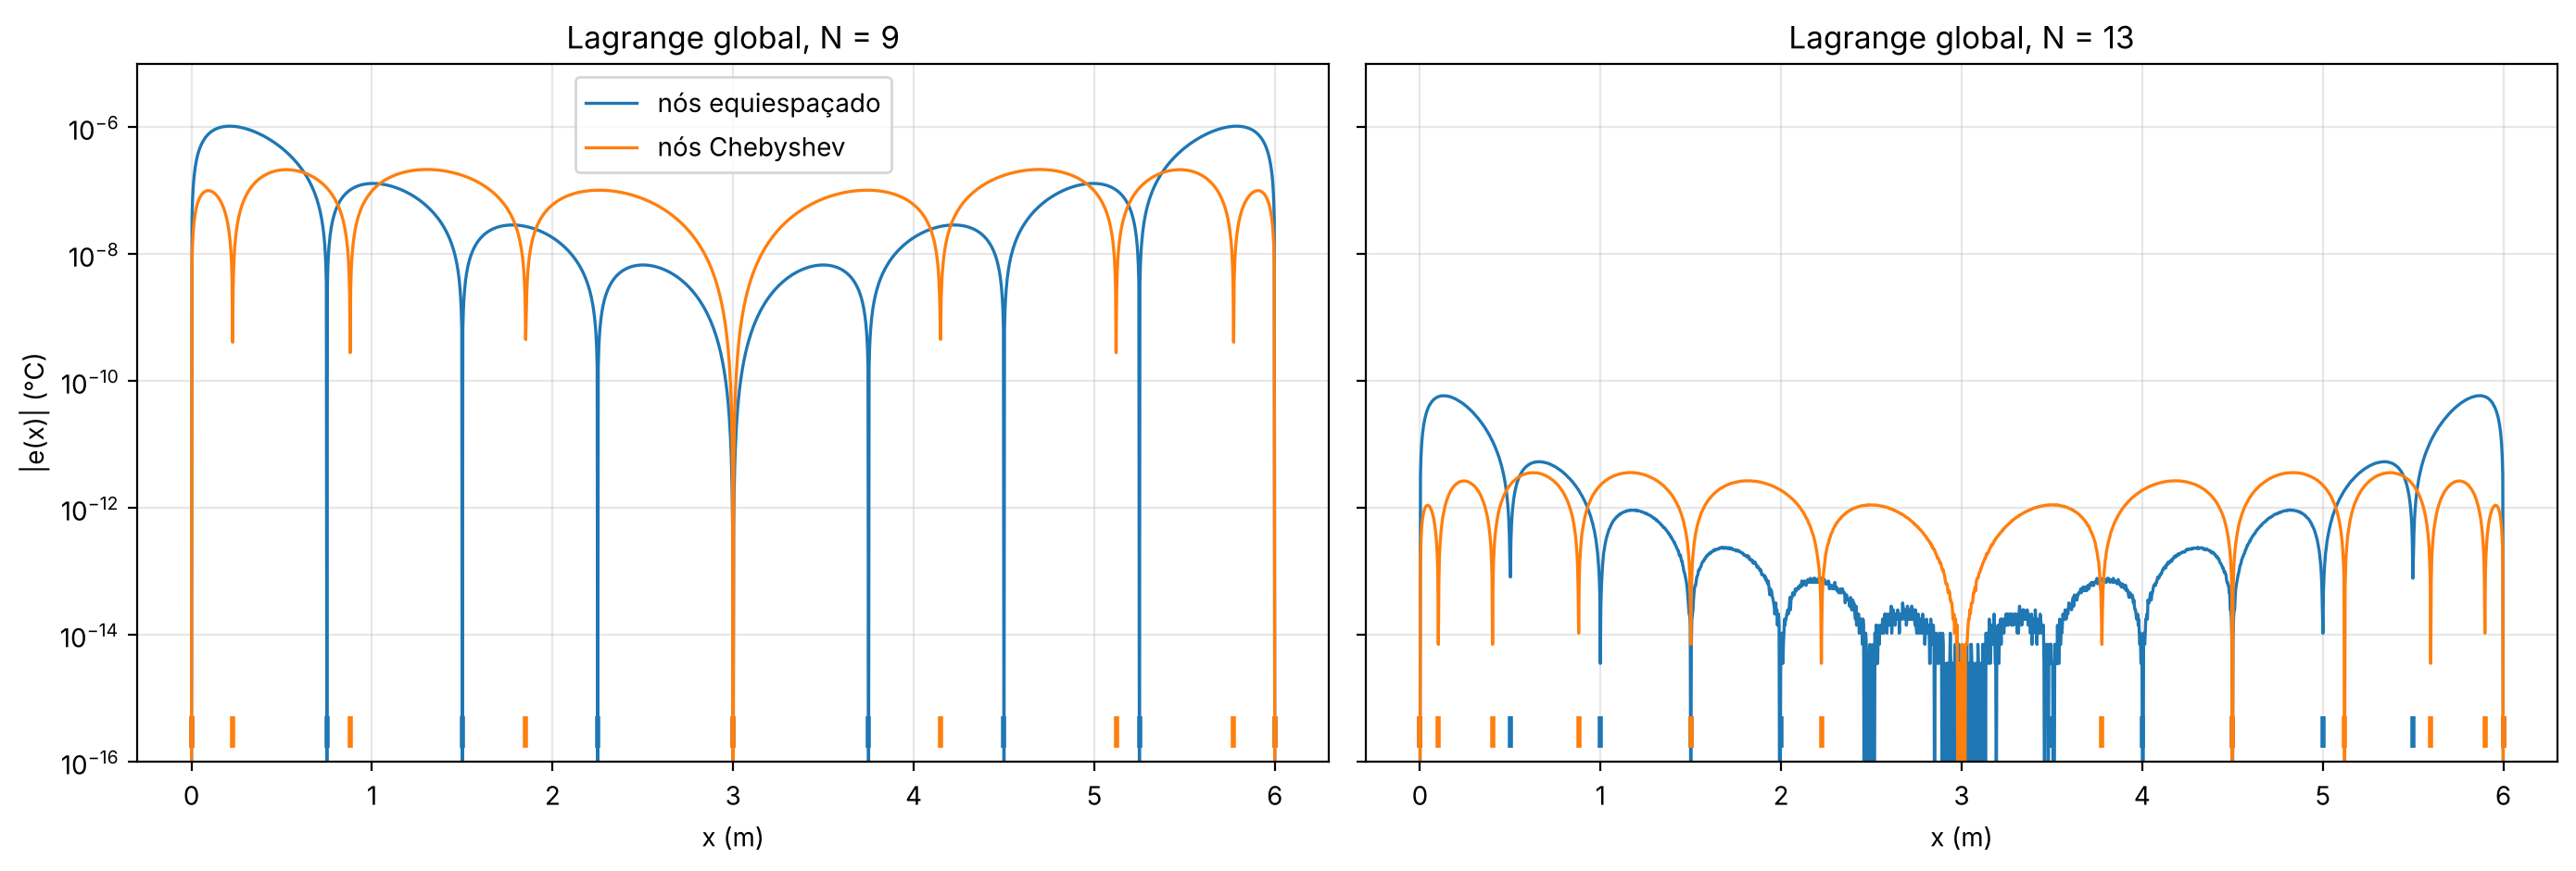

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, N in zip(axs, [9, 13]):
    for tipo, xs, cor in [("equiespaçado", np.linspace(x_min, x_max, N), "tab:blue"),
                          ("Chebyshev", nos_chebyshev_lobatto(x_min, x_max, N), "tab:orange")]:
        p = BarycentricInterpolator(xs, temperatura_real(xs))
        ax.semilogy(x_fino, np.abs(p(x_fino) - T_fino) + 1e-17, color=cor, lw=1.2, label=f"nós {tipo}")
        ax.plot(xs, np.full(N, 3e-16), "|", color=cor, ms=12, mew=2)
    ax.set_ylim(1e-16, 1e-5)
    ax.set_title(f"Lagrange global, N = {N}")
    ax.set_xlabel("x (m)")
    ax.grid(alpha=0.3, which="both")
axs[0].set_ylabel("|e(x)| (°C)")
axs[0].legend(loc="upper center")
plt.tight_layout()
plt.show()

Análise da etapa 2

Nos dois casos o erro cai muito rápido com N, e o Chebyshev foi melhor em todos. Em N = 5 o erro máximo foi 4,5e-3 °C no equiespaçado contra 2,3e-3 °C no Chebyshev, e em N = 13 foi 5,9e-11 °C contra 3,6e-12 °C. Em N = 17 o Chebyshev já chega em 1e-14, que é basicamente o limite de precisão do computador. O RMSE seguiu a mesma tendência.

No gráfico dá pra ver que com nós equiespaçados o erro se acumula nas pontas, enquanto com Chebyshev ele fica espalhado por igual. No meio da barra o equiespaçado é até melhor, mas o erro máximo é decidido nas pontas. Não apareceu o fenômeno de Runge porque o perfil (reta mais seno) é muito suave. Com uma função menos comportada o equiespaçado poderia oscilar bem mais, então não dá pra generalizar esse resultado pra qualquer perfil.

## Etapa 3 — Estudo de caso e decisão técnica

Faça $N$ variar de 4 a 40. Compare erro máximo e RMSE em escala logarítmica para Lagrange equiespaçado, Lagrange com Chebyshev e spline cúbica natural. Registre o tempo de construção e de avaliação. Discuta o custo e a estabilidade numérica.

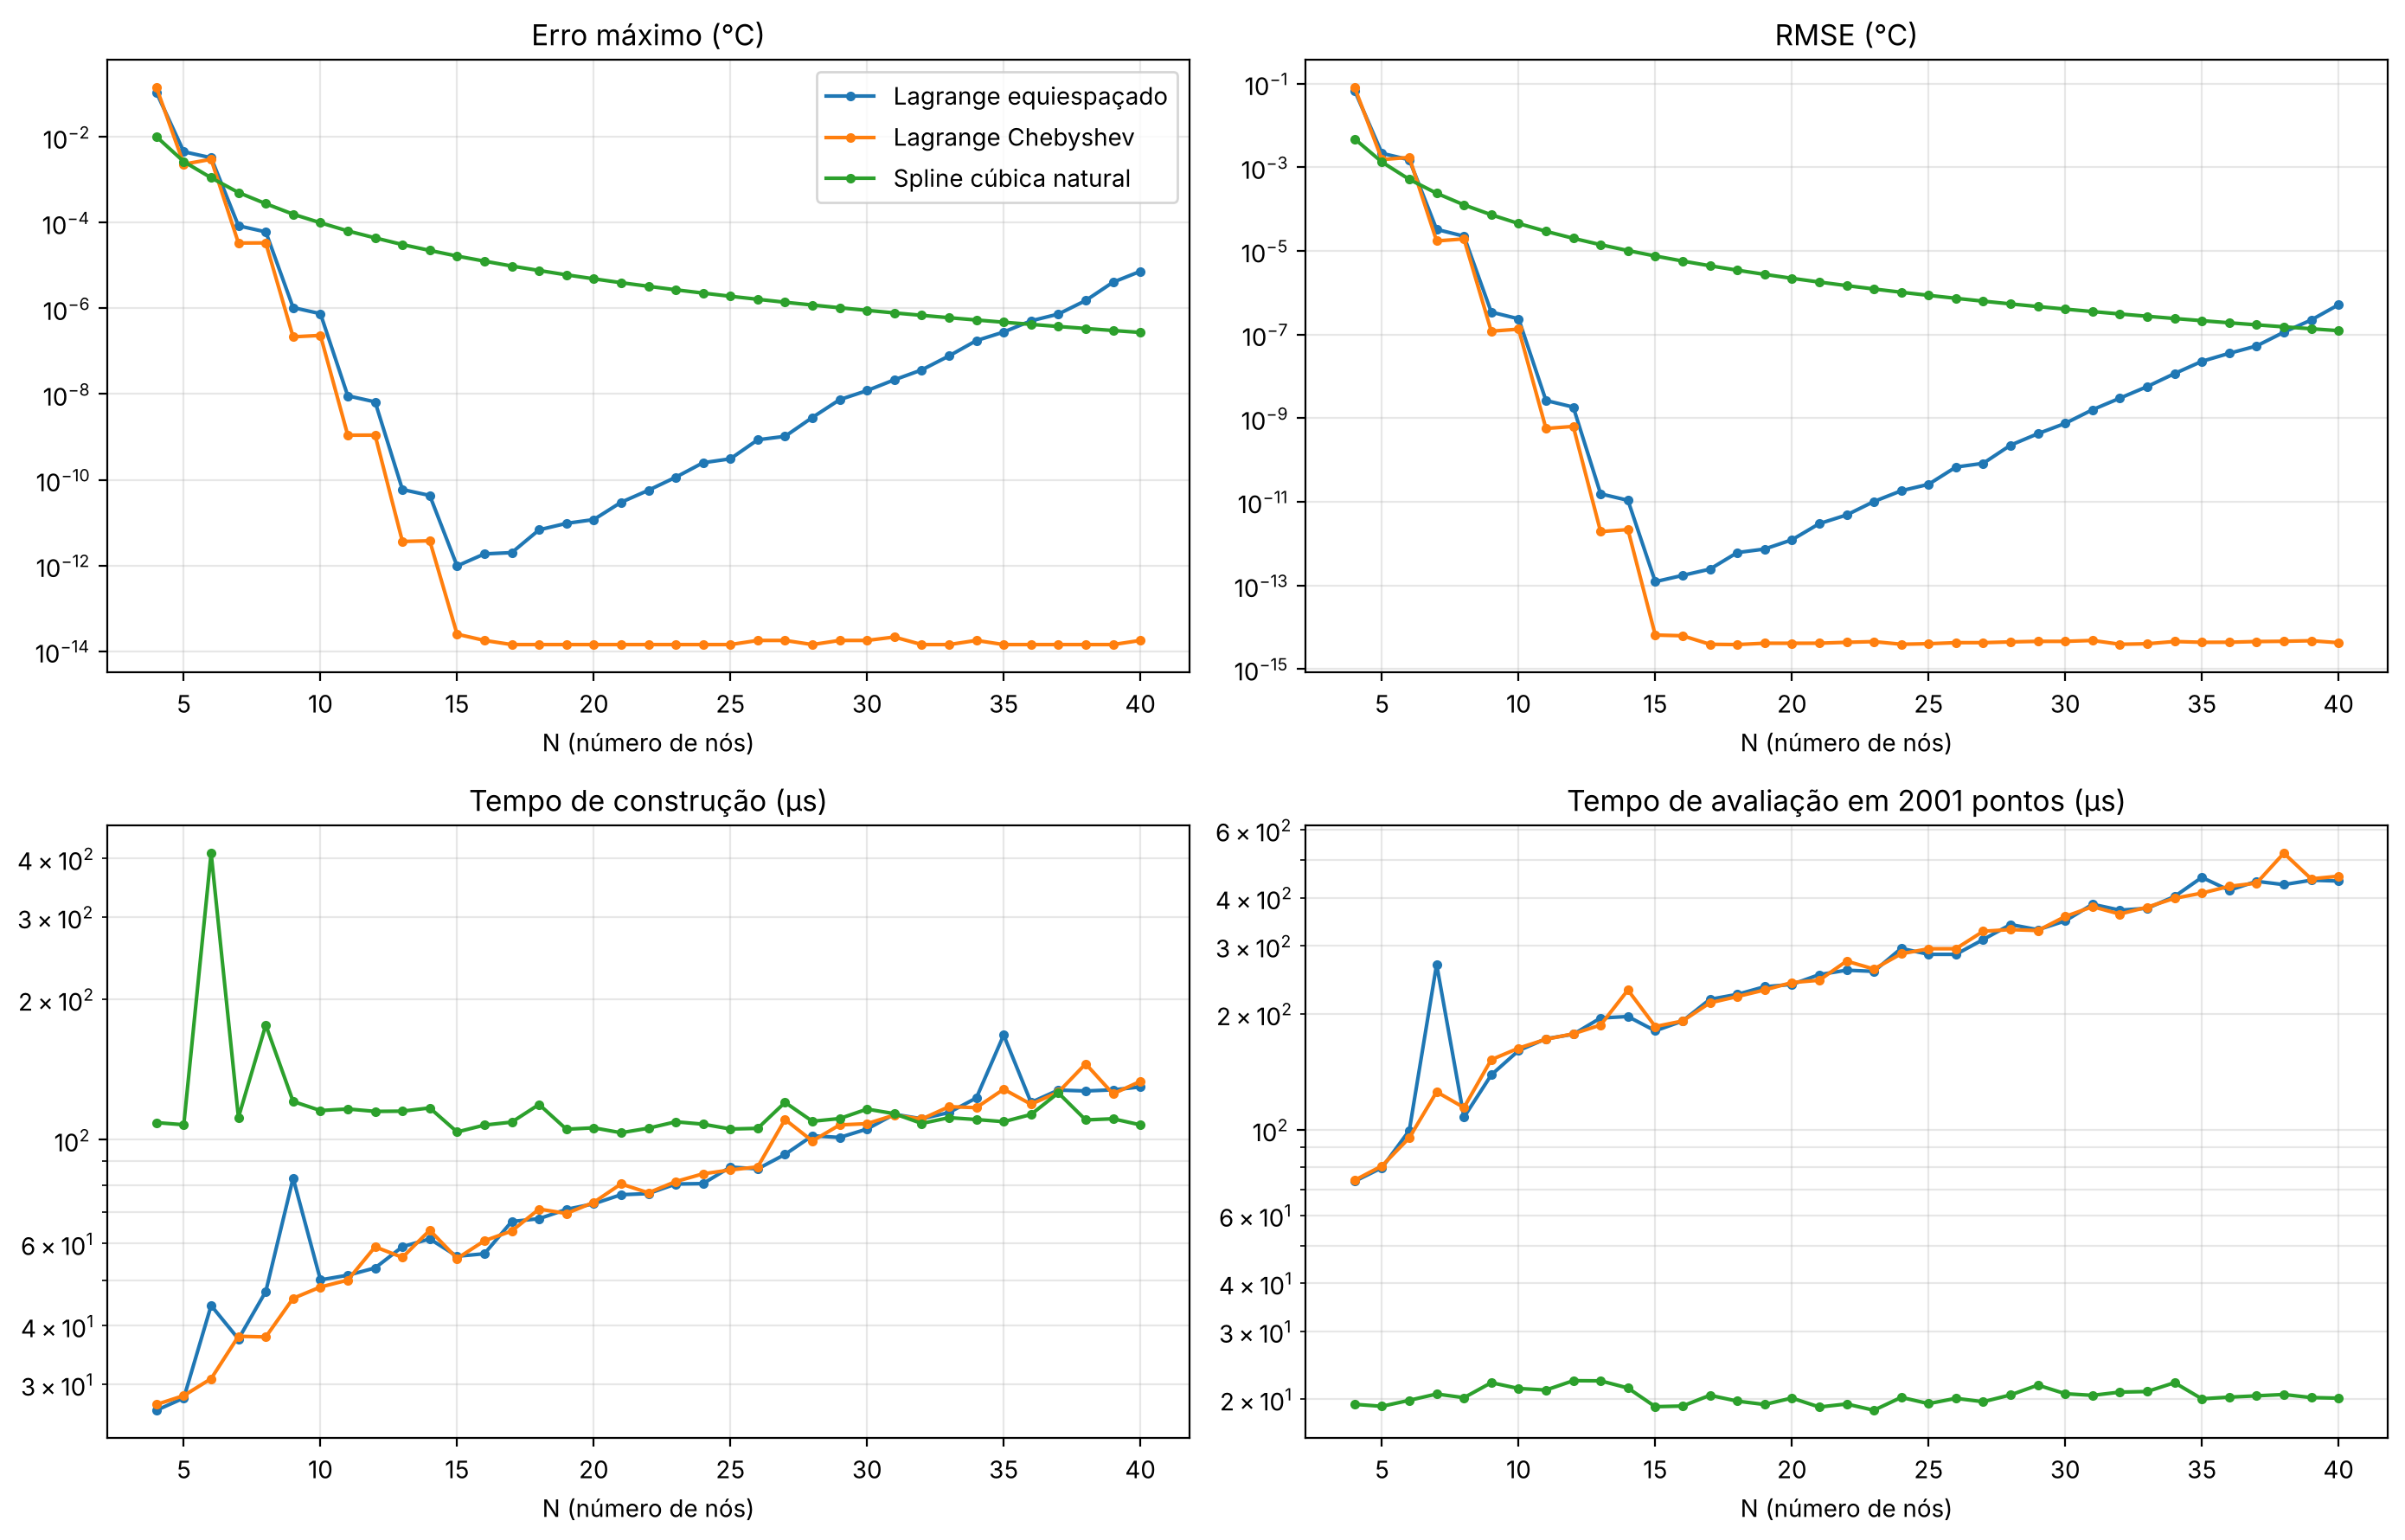

Método,Lagrange Chebyshev,Lagrange equiespaçado,Spline cúbica natural
N,,,
4,1.430e-01,1.090e-01,1.018e-02
5,2.327e-03,4.530e-03,2.665e-03
6,3.017e-03,3.282e-03,1.118e-03
7,3.352e-05,8.468e-05,5.060e-04
10,2.338e-07,7.517e-07,9.963e-05
15,2.487e-14,9.734e-13,1.661e-05
20,1.421e-14,1.175e-11,4.900e-06
30,1.776e-14,1.205e-08,8.993e-07
35,1.421e-14,2.805e-07,4.749e-07


Lagrange equiespaçado tem o menor Emax para N = []
Lagrange Chebyshev tem o menor Emax para N = [5, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40]
Spline cúbica natural tem o menor Emax para N = [4, 6]


In [ ]:
import time

def cronometrar(funcao, repeticoes=25):
    tempos = []
    for _ in range(repeticoes):
        t0 = time.perf_counter()
        funcao()
        tempos.append(time.perf_counter() - t0)
    return np.median(tempos)

def spline_natural(x, y):
    return CubicSpline(x, y, bc_type="natural")

casos = {"Lagrange equiespaçado": (lambda N: np.linspace(x_min, x_max, N), BarycentricInterpolator),
         "Lagrange Chebyshev": (lambda N: nos_chebyshev_lobatto(x_min, x_max, N), BarycentricInterpolator),
         "Spline cúbica natural": (lambda N: np.linspace(x_min, x_max, N), spline_natural)}

linhas = []
for N in range(4, 41):
    for nome, (gera_nos, construtor) in casos.items():
        xs = gera_nos(N)
        ys = temperatura_real(xs)
        interp = construtor(xs, ys)
        erro = interp(x_fino) - T_fino
        linhas.append({"N": N, "Método": nome,
                       "Emax (°C)": np.max(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2)),
                       "t construção (µs)": 1e6*cronometrar(lambda: construtor(xs, ys)),
                       "t avaliação (µs)": 1e6*cronometrar(lambda: interp(x_fino))})

estudo = pd.DataFrame(linhas)

fig, axs = plt.subplots(2, 2, figsize=(14, 9))
for nome, cor in zip(casos, ["tab:blue", "tab:orange", "tab:green"]):
    d = estudo[estudo["Método"] == nome]
    axs[0, 0].semilogy(d["N"], d["Emax (°C)"], "o-", ms=3, color=cor, label=nome)
    axs[0, 1].semilogy(d["N"], d["RMSE (°C)"], "o-", ms=3, color=cor, label=nome)
    axs[1, 0].semilogy(d["N"], d["t construção (µs)"], "o-", ms=3, color=cor, label=nome)
    axs[1, 1].semilogy(d["N"], d["t avaliação (µs)"], "o-", ms=3, color=cor, label=nome)
titulos = ["Erro máximo (°C)", "RMSE (°C)", "Tempo de construção (µs)", "Tempo de avaliação em 2001 pontos (µs)"]
for ax, titulo in zip(axs.ravel(), titulos):
    ax.set_title(titulo)
    ax.set_xlabel("N (número de nós)")
    ax.grid(alpha=0.3, which="both")
axs[0, 0].legend()
plt.tight_layout()
plt.show()

selecao = estudo[estudo["N"].isin([4, 5, 6, 7, 10, 15, 20, 30, 35, 36, 40])]
display(selecao.pivot(index="N", columns="Método", values="Emax (°C)"))

melhor = estudo.loc[estudo.groupby("N")["Emax (°C)"].idxmin(), ["N", "Método"]]
for nome in casos:
    print(f"{nome} tem o menor Emax para N = {melhor[melhor['Método'] == nome]['N'].tolist()}")

In [ ]:
pd.set_option("display.float_format", "{:.4g}".format)
tempos = estudo[estudo["N"].isin([4, 10, 20, 30, 40])].pivot(index="N", columns="Método",
                                                              values=["t construção (µs)", "t avaliação (µs)"])
display(tempos)

def constante_lebesgue(xs):
    base = BarycentricInterpolator(xs, np.eye(len(xs)))
    return np.max(np.sum(np.abs(base(x_fino)), axis=1))

lebesgue = pd.DataFrame([{"N": N,
                          "Lebesgue equiespaçado": constante_lebesgue(np.linspace(x_min, x_max, N)),
                          "Lebesgue Chebyshev": constante_lebesgue(nos_chebyshev_lobatto(x_min, x_max, N))}
                         for N in [5, 10, 15, 20, 25, 30, 35, 40]]).set_index("N")
display(lebesgue)

d_eq = estudo[estudo["Método"] == "Lagrange equiespaçado"].set_index("N")["Emax (°C)"]
d_sp = estudo[estudo["Método"] == "Spline cúbica natural"].set_index("N")["Emax (°C)"]
print("razão de redução do erro da spline quando N vai de 20 para 39 (h cai pela metade):", round(d_sp[20]/d_sp[39], 1))
print("menor erro do Lagrange equiespaçado:", f"{d_eq.min():.2e}", "em N =", d_eq.idxmin())

t construção (µs)                                              \
Método Lagrange Chebyshev Lagrange equiespaçado Spline cúbica natural   
N                                                                       
4                   27.15                 26.39                 108.9   
10                  48.44                 50.17                 115.5   
20                  73.49                 72.97                 106.1   
30                  108.3                 105.5                 116.3   
40                  133.4                 129.8                 107.7   

         t avaliação (µs)                                              
Método Lagrange Chebyshev Lagrange equiespaçado Spline cúbica natural  
N                                                                      
4                   73.93                 73.46                 19.39  
10                  162.8                 160.4                 21.31  
20                  240.9                 238.1                 20.13  
30                  357.3                 348.1                 20.65  
40                  454.6                 441.8                 20.11

,Lebesgue equiespaçado,Lebesgue Chebyshev
N,,
5,2.208,1.799
10,17.85,2.362
15,283.2,2.639
20,5889,2.837
25,1.379e+05,2.984
30,3.448e+06,3.106
35,9.001e+07,3.207
40,2.422e+09,3.295


razão de redução do erro da spline quando N vai de 20 para 39 (h cai pela metade): 16.1
menor erro do Lagrange equiespaçado: 9.73e-13 em N = 15


Análise da etapa 3

O Chebyshev chega no limite da máquina (uns 1e-14 °C) por volta de N = 15 e fica lá. O equiespaçado também cai até mais ou menos N = 15, mas depois volta a subir e chega na casa de 1e-5 °C em N = 40. Isso não é falta de precisão do polinômio, é erro de arredondamento sendo amplificado. A constante de Lebesgue mostra bem isso: nos nós equiespaçados ela vai de 18 (N = 10) para 2,4e9 (N = 40), enquanto no Chebyshev fica em torno de 3. A spline cai certinho como h^4, quando h cai pela metade (N de 20 para 39) o erro cai 16 vezes.

Então não tem um método que ganha sempre. A spline foi a melhor com N = 4 e N = 6, o Chebyshev ganhou no resto, e o equiespaçado é melhor que a spline de N = 7 até uns 35, mas perde depois disso. Uma coisa curiosa é que o Lagrange melhora de dois em dois (5 e 6 dão quase o mesmo erro, 7 e 8 também), por causa da simetria do seno em torno do meio da barra.

Sobre custo, tudo ficou em microssegundos. A spline levou uns 110 µs pra montar e uns 20 µs pra avaliar, quase sem mudar com N. O Lagrange fica mais caro conforme N cresce (avaliação de uns 75 µs em N = 4 para uns 450 µs em N = 40), porque cada ponto avaliado usa todos os nós. Com poucos sensores isso não faz diferença, mas a spline escala melhor e é mais estável. O problema do Chebyshev é que ele exige sensores em posições bem específicas, o que nem sempre dá pra fazer na prática.

## Etapa 4 — Estudo de caso e decisão técnica

Uma equipe precisa estimar a temperatura em posições internas da barra, com sensores ruidosos. Não haverá sensores em todos os pontos e a solução verdadeira será desconhecida em campo.


Teste com ruído

Pra simular sensores reais, somamos um ruído gaussiano de desvio padrão 0,1 °C nas leituras e repetimos 300 vezes para cada N. Além do Lagrange e da spline cúbica, testamos também uma spline de suavização (make_smoothing_spline), que não passa exatamente pelos pontos. O erro é sempre calculado em relação à temperatura verdadeira.

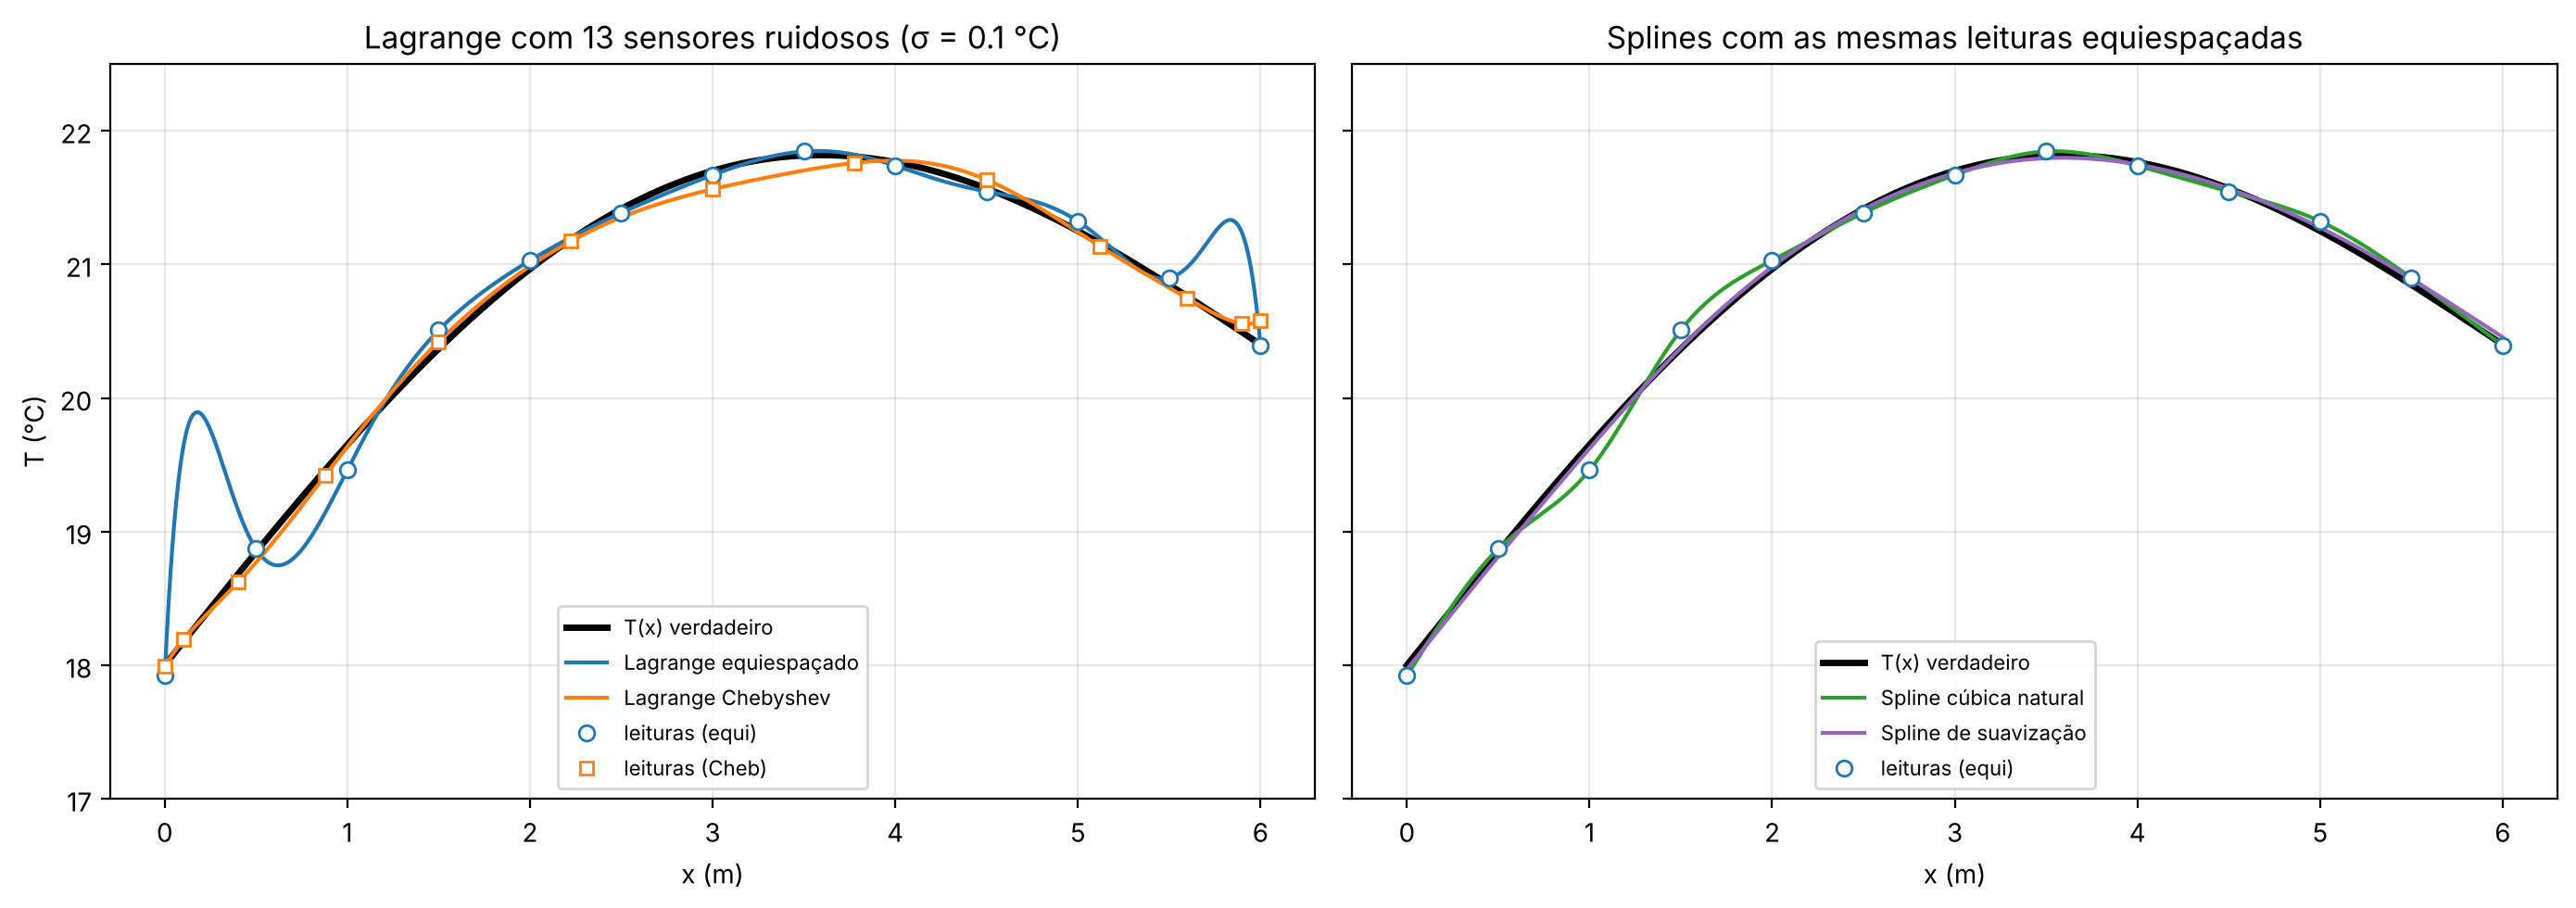

In [ ]:
from scipy.interpolate import make_smoothing_spline

sigma = 0.1
rng = np.random.default_rng(2026)

N_ex = 13
x_eq = np.linspace(x_min, x_max, N_ex)
x_ch = nos_chebyshev_lobatto(x_min, x_max, N_ex)
y_eq = temperatura_real(x_eq) + rng.normal(0, sigma, N_ex)
y_ch = temperatura_real(x_ch) + rng.normal(0, sigma, N_ex)

fig, axs = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
axs[0].plot(x_fino, T_fino, "k", lw=2.5, label="T(x) verdadeiro")
axs[0].plot(x_fino, BarycentricInterpolator(x_eq, y_eq)(x_fino), color="tab:blue", label="Lagrange equiespaçado")
axs[0].plot(x_fino, BarycentricInterpolator(x_ch, y_ch)(x_fino), color="tab:orange", label="Lagrange Chebyshev")
axs[0].plot(x_eq, y_eq, "o", color="tab:blue", mfc="white", label="leituras (equi)")
axs[0].plot(x_ch, y_ch, "s", color="tab:orange", mfc="white", ms=5, label="leituras (Cheb)")
axs[0].set_title(f"Lagrange com {N_ex} sensores ruidosos (σ = {sigma} °C)")

axs[1].plot(x_fino, T_fino, "k", lw=2.5, label="T(x) verdadeiro")
axs[1].plot(x_fino, CubicSpline(x_eq, y_eq, bc_type="natural")(x_fino), color="tab:green", label="Spline cúbica natural")
axs[1].plot(x_fino, make_smoothing_spline(x_eq, y_eq)(x_fino), color="tab:purple", label="Spline de suavização")
axs[1].plot(x_eq, y_eq, "o", color="tab:blue", mfc="white", label="leituras (equi)")
axs[1].set_title("Splines com as mesmas leituras equiespaçadas")
for ax in axs:
    ax.set_ylim(17.0, 22.5)
    ax.set_xlabel("x (m)")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower center", fontsize=8)
axs[0].set_ylabel("T (°C)")
plt.tight_layout()
plt.show()

Média de 300 repetições com ruído gaussiano de desvio padrão 0.1 °C
RMSE médio (°C):


Método,Lagrange equiespaçado,Lagrange Chebyshev,Spline cúbica natural,Spline de suavização
N,,,,
5,0.0983,0.09,0.0848,0.0822
7,0.119,0.0914,0.088,0.0777
9,0.179,0.0982,0.0874,0.0711
13,0.793,0.0961,0.0897,0.0607
17,6.6,0.1,0.0902,0.0541
21,63.2,0.0992,0.0933,0.0485
25,667,0.0968,0.0907,0.0466


Erro máximo médio (°C):


Método,Lagrange equiespaçado,Lagrange Chebyshev,Spline cúbica natural,Spline de suavização
N,,,,
5,0.182,0.166,0.161,0.157
7,0.258,0.181,0.179,0.156
9,0.514,0.205,0.186,0.148
13,3.35,0.213,0.204,0.13
17,33,0.231,0.217,0.124
21,359,0.244,0.229,0.112
25,4.14e+03,0.244,0.228,0.112


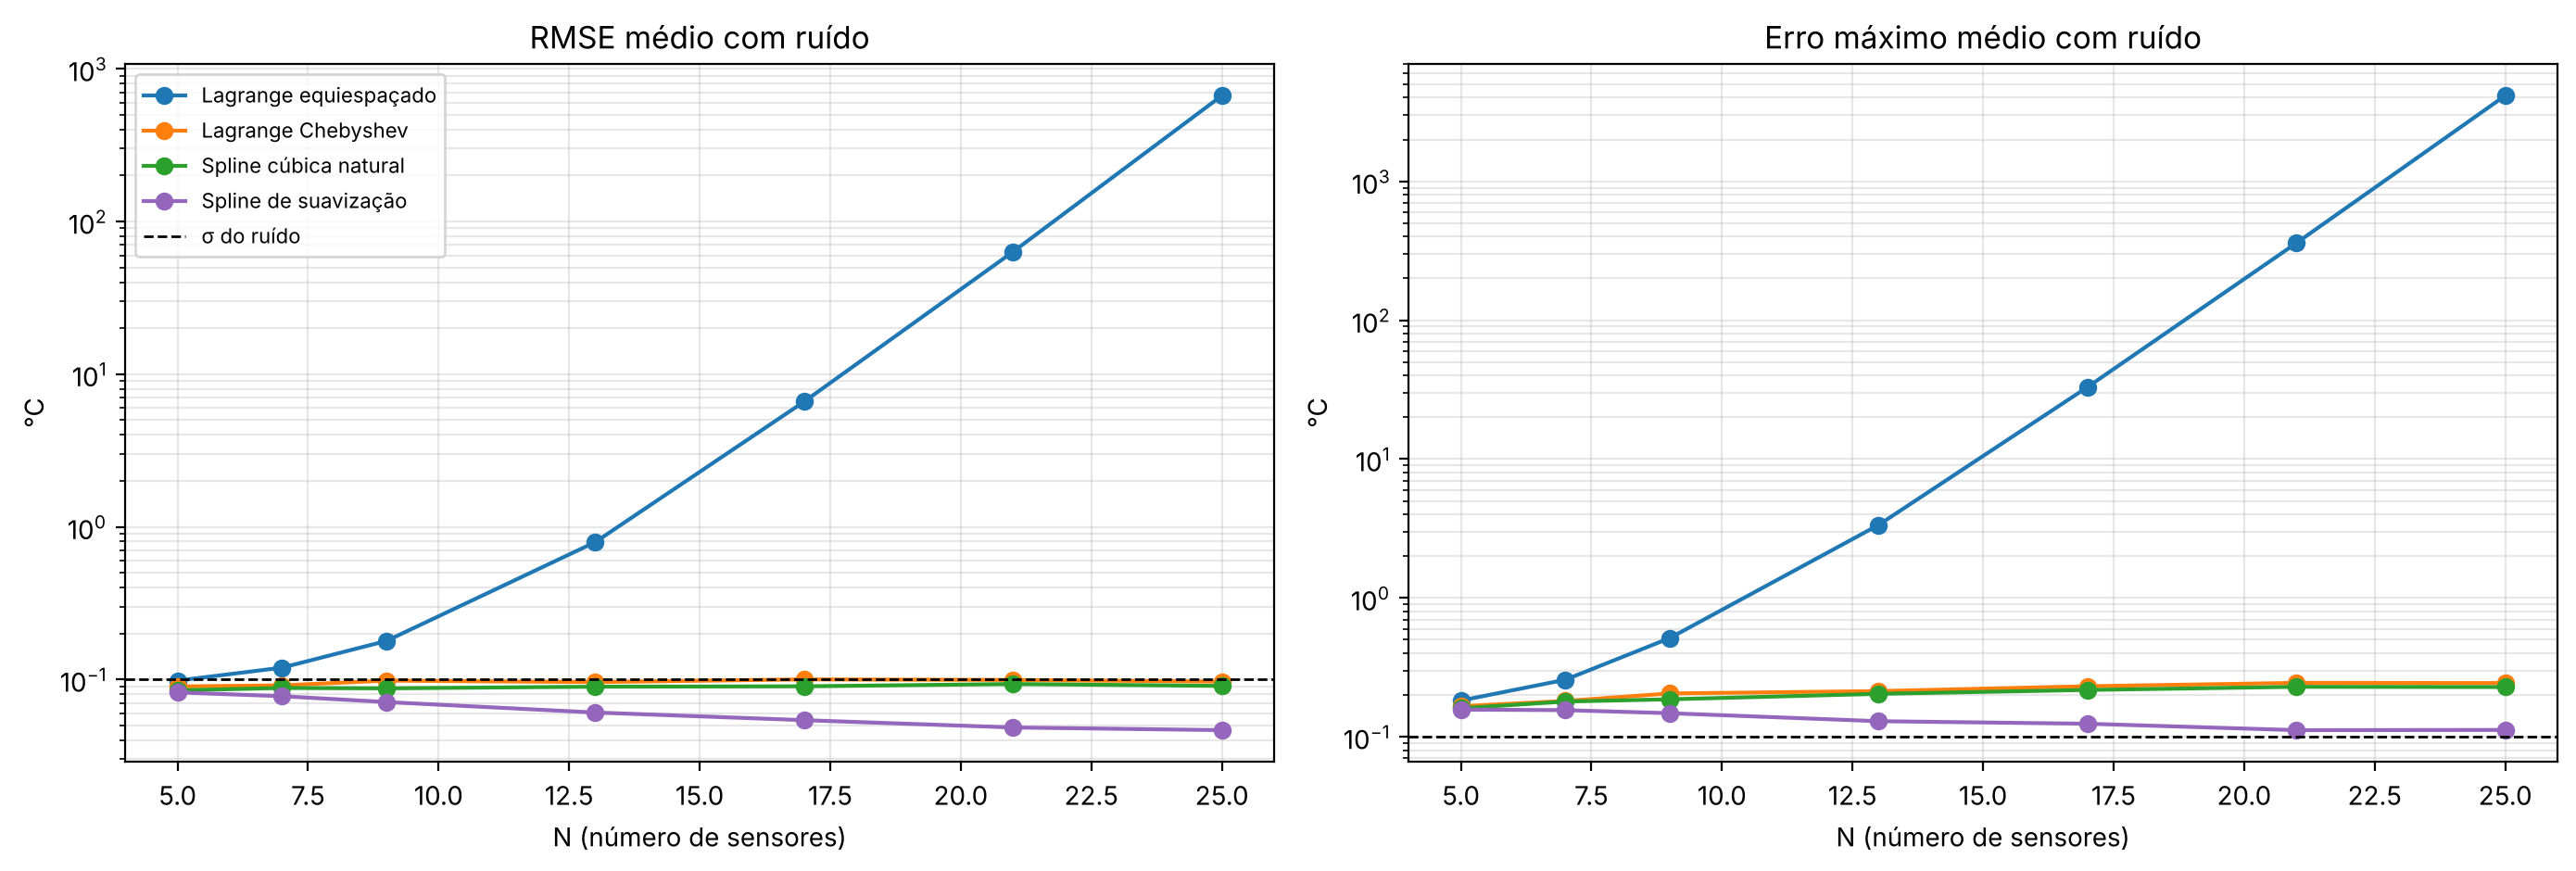

In [ ]:
pd.set_option("display.float_format", "{:.3g}".format)

def ajustar(nome, x, y):
    if nome.startswith("Lagrange"):
        return BarycentricInterpolator(x, y)
    if nome == "Spline cúbica natural":
        return CubicSpline(x, y, bc_type="natural")
    return make_smoothing_spline(x, y)

nomes_ruido = ["Lagrange equiespaçado", "Lagrange Chebyshev", "Spline cúbica natural", "Spline de suavização"]
R = 300
linhas = []
for N in [5, 7, 9, 13, 17, 21, 25]:
    for nome in nomes_ruido:
        xs = nos_chebyshev_lobatto(x_min, x_max, N) if "Chebyshev" in nome else np.linspace(x_min, x_max, N)
        emax, rmse = [], []
        for _ in range(R):
            ys = temperatura_real(xs) + rng.normal(0, sigma, N)
            erro = ajustar(nome, xs, ys)(x_fino) - T_fino
            emax.append(np.max(np.abs(erro)))
            rmse.append(np.sqrt(np.mean(erro**2)))
        linhas.append({"N": N, "Método": nome,
                       "Emax médio (°C)": np.mean(emax),
                       "RMSE médio (°C)": np.mean(rmse)})

ruido = pd.DataFrame(linhas)
print(f"Média de {R} repetições com ruído gaussiano de desvio padrão {sigma} °C")
print("RMSE médio (°C):")
display(ruido.pivot(index="N", columns="Método", values="RMSE médio (°C)")[nomes_ruido])
print("Erro máximo médio (°C):")
display(ruido.pivot(index="N", columns="Método", values="Emax médio (°C)")[nomes_ruido])

fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))
for nome, cor in zip(nomes_ruido, ["tab:blue", "tab:orange", "tab:green", "tab:purple"]):
    d = ruido[ruido["Método"] == nome]
    axs[0].semilogy(d["N"], d["RMSE médio (°C)"], "o-", color=cor, label=nome)
    axs[1].semilogy(d["N"], d["Emax médio (°C)"], "o-", color=cor, label=nome)
for ax, titulo in zip(axs, ["RMSE médio com ruído", "Erro máximo médio com ruído"]):
    ax.axhline(sigma, color="k", ls="--", lw=1, label="σ do ruído")
    ax.set_title(titulo)
    ax.set_xlabel("N (número de sensores)")
    ax.set_ylabel("°C")
    ax.grid(alpha=0.3, which="both")
axs[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

Com ruído o Lagrange equiespaçado fica inutilizável: o RMSE médio foi de 0,79 °C em N = 13 e 6,6 °C em N = 17, e o erro máximo médio passou de 30 °C em N = 17, numa barra que fica entre 18 e 22 °C. É o mesmo problema de amplificação da etapa 3, só que agora com um erro de 0,1 °C.

O Lagrange com Chebyshev e a spline cúbica ficaram estáveis, com RMSE em torno de 0,09 °C, ou seja, do tamanho do ruído. Mas colocar mais sensores não ajudou, porque eles passam exatamente por cada leitura e copiam o ruído junto. A única que melhorou com mais sensores foi a spline de suavização (RMSE de 0,082 °C com N = 5 para 0,047 °C com N = 25).

Por último testamos extrapolação, com sensores só até 4,5 m.

In [ ]:
x_parcial = np.linspace(0, 4.5, 7)
x_fora = np.array([4.5, 5.0, 5.5, 6.0])
T_fora = temperatura_real(x_fora)

linhas = []
for nome, construtor in [("Lagrange", BarycentricInterpolator), ("Spline cúbica natural", spline_natural)]:
    p = construtor(x_parcial, temperatura_real(x_parcial))
    linhas.append([nome, "dados exatos"] + list(np.abs(p(x_fora) - T_fora)))
    erros = []
    for _ in range(R):
        p_r = construtor(x_parcial, temperatura_real(x_parcial) + rng.normal(0, sigma, len(x_parcial)))
        erros.append(np.abs(p_r(x_fora) - T_fora))
    linhas.append([nome, f"ruído σ={sigma} (média)"] + list(np.mean(erros, axis=0)))

extrapolacao = pd.DataFrame(linhas, columns=["Método", "Caso"] + [f"|e| em x={v} m" for v in x_fora])
print("Sensores só entre 0 e 4,5 m; avaliação fora do intervalo medido")
display(extrapolacao)

Sensores só entre 0 e 4,5 m; avaliação fora do intervalo medido


,Método,Caso,|e| em x=4.5 m,|e| em x=5.0 m,|e| em x=5.5 m,|e| em x=6.0 m
0,Lagrange,dados exatos,0,0.000277,0.00136,0.00403
1,Lagrange,ruído σ=0.1 (média),0.0803,2,9.46,29.1
2,Spline cúbica natural,dados exatos,0,0.13,0.473,1.12
3,Spline cúbica natural,ruído σ=0.1 (média),0.0813,0.194,0.489,1.15


Recomendação

Com poucos sensores e dados exatos a gente usaria o Lagrange de grau baixo, de preferência com os sensores nas posições de Chebyshev. Com 7 sensores ele teve Emax de 8,5e-5 °C e RMSE de 3,3e-5 °C, contra 5,1e-4 °C e 2,4e-4 °C da spline cúbica. Mas a spline fica bem perto e é mais segura, então também seria uma boa escolha.

Com mais sensores a gente trocaria pra spline cúbica. O Lagrange equiespaçado para de melhorar perto de 15 sensores e depois piora, e com ruído ele já começa a piorar antes de 10. A spline continua melhorando, é barata e estável.

Com ruído a gente não usaria interpolação exata, porque qualquer método que passa pelos pontos fica com erro do tamanho do ruído. O melhor foi usar um ajuste suavizado, como a spline de suavização. Também ajudaria fazer várias leituras em cada sensor e tirar a média, já que o regime é estacionário.

Nas pontas é onde o polinômio global mais erra, então é bom ter sensores nas extremidades ou usar as temperaturas de contorno, que são conhecidas (18 °C e 20,4 °C). A condição natural da spline só funcionou bem aqui porque a fonte de calor é zero nas pontas; em outro caso seria melhor usar outra condição de contorno.

Tudo isso vale dentro do intervalo medido. Fora dele (extrapolação) nenhum método foi confiável: com sensores só até 4,5 m, a spline errou 1,12 °C em x = 6 m mesmo sem ruído, e o Lagrange com ruído errou em média 29 °C no mesmo ponto.

Por fim, em campo não dá pra calcular Emax nem RMSE, porque a temperatura verdadeira não é conhecida. Dá pra fazer validação cruzada (tirar um sensor e ver se os outros acertam ele), mas isso só testa nos pontos dos sensores. E os nossos resultados dependem do perfil ser suave; numa barra real pode ter perda de calor pelas laterais, sensor com erro sistemático e incerteza na posição dos sensores.

Conclusão

No geral, com dados exatos mais sensores sempre ajudam, desde que não se use polinômio global equiespaçado com muitos pontos. A posição dos sensores importa muito para o Lagrange e pouco para a spline. E o ruído é o que mais pesa: com ele as diferenças entre os métodos quase somem, e só um ajuste que suaviza consegue melhorar com mais sensores.